# CORD-v2: a one-page EDA

How many receipts / words / entities there are, and how unevenly the fields are distributed. Entities follow the project's labelling: one entity per annotated line, key words such as `TOTAL` excluded (see `src/receipt/data.py`).

In [1]:
import collections
import matplotlib.pyplot as plt
import pandas as pd
from receipt.bio import bio_entities
from receipt.data import load_split

splits = {s: load_split(s) for s in ['train', 'validation', 'test']}

/Users/lsh/Desktop/receipt-ml-project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using the latest cached version of the dataset since naver-clova-ix/cord-v2 couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /Users/lsh/.cache/huggingface/datasets/naver-clova-ix___cord-v2/default/0.0.0/7f0115a4b758a71d6473b8d085751692da2fef98 (last modified on Sun Oct 25 22:55:43 2026).


Using the latest cached version of the dataset since naver-clova-ix/cord-v2 couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /Users/lsh/.cache/huggingface/datasets/naver-clova-ix___cord-v2/default/0.0.0/7f0115a4b758a71d6473b8d085751692da2fef98 (last modified on Sun Oct 25 22:55:43 2026).


Using the latest cached version of the dataset since naver-clova-ix/cord-v2 couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /Users/lsh/.cache/huggingface/datasets/naver-clova-ix___cord-v2/default/0.0.0/7f0115a4b758a71d6473b8d085751692da2fef98 (last modified on Sun Oct 25 22:55:43 2026).


## Receipts, words and entities per split

In [2]:
rows = []
for s, rs in splits.items():
    words = pd.Series([len(r.words) for r in rs])
    ents = pd.Series([len(bio_entities(r.tags)) for r in rs])
    rows.append({'split': s, 'receipts': len(rs), 'words/receipt (mean)': words.mean(),
                 'words/receipt (median)': words.median(), 'words/receipt (max)': words.max(),
                 'entities/receipt (mean)': ents.mean(), 'entities (total)': ents.sum(),
                 'words tagged O (%)': 100 * sum(t == 'O' for r in rs for t in r.tags) / words.sum()})
pd.DataFrame(rows).set_index('split').round(1)

,receipts,words/receipt (mean),words/receipt (median),words/receipt (max),entities/receipt (mean),entities (total),words tagged O (%)
split,,,,,,,
train,800,24.2,20.0,135,13.7,10947,24.2
validation,100,21.9,20.0,70,12.2,1219,23.7
test,100,23.6,20.0,66,13.0,1301,24.4


## Entities per field

In [3]:
counts = pd.DataFrame({s: collections.Counter(e[0] for r in rs for e in bio_entities(r.tags))
                       for s, rs in splits.items()}).fillna(0).astype(int)
counts = counts.sort_values('train', ascending=False)
counts

,train,validation,test
menu.nm,2100,222,251
menu.price,2093,220,246
menu.cnt,1902,210,220
total.total_price,780,98,95
menu.unitprice,620,50,67
sub_total.subtotal_price,538,67,66
total.cashprice,523,64,69
total.changeprice,501,64,56
sub_total.tax_price,360,47,44
menu.sub.nm,319,49,36


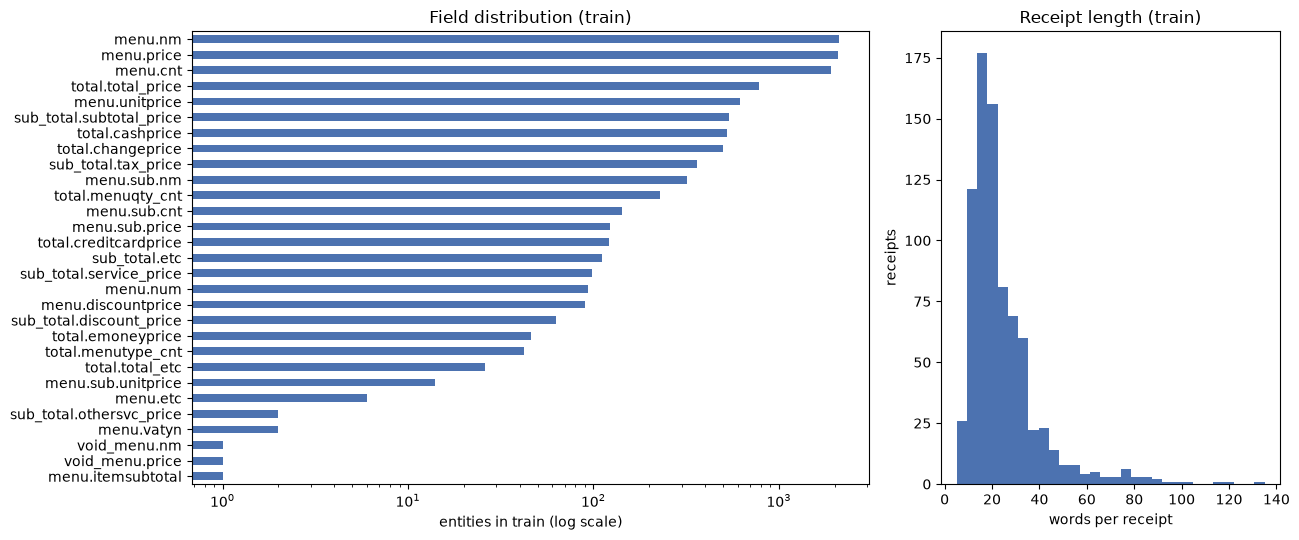

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={'width_ratios': [2, 1]})
counts['train'].plot.barh(ax=axes[0], color='#4C72B0', logx=True)
axes[0].invert_yaxis()
axes[0].set_xlabel('entities in train (log scale)')
axes[0].set_title('Field distribution (train)')
axes[1].hist([len(r.words) for r in splits['train']], bins=30, color='#4C72B0')
axes[1].set_xlabel('words per receipt')
axes[1].set_ylabel('receipts')
axes[1].set_title('Receipt length (train)')
plt.tight_layout()

**Takeaways.** The fields are very unbalanced: `menu.nm`, `menu.price` and `menu.cnt` make up most entities, while several fields have only a handful of training examples (they will have unstable or zero F1, so per-field scores for rare fields should not be over-read; micro F1 is dominated by the frequent fields). Receipts are short (median ~20 words), so nothing comes close to the 512-token limit. `total.total_price` occurs about once per receipt, which is why it is the field the rule baseline targets.